# 10 — Bonus Distribution per Team (2025/26 retrospective)

Bonus points (the BPS podium — 3/2/1 per match) are noisy game-by-game but tell a real story
over a season: *which clubs' assets banked the extra points, and who inside each squad earned
them.* This notebook attributes every one of the season's bonus points to a **team**, then
splits each team's haul **by position** and **by player**.

- **Data:** vaastav `2025-26/gws/merged_gw.csv` only — raw per-GW `bonus` counts, no fixtures.
- **Question:** by team → by position → by player, where did the bonus come from?

In [31]:
SEASON = "2025-26"
BASE   = f"https://raw.githubusercontent.com/vaastav/Fantasy-Premier-League/master/data/{SEASON}"
MERGED_URL = f"{BASE}/gws/merged_gw.csv"

POS_ORDER = ["GK", "DEF", "MID", "FWD"]
TOP_PLAYERS = 20   # leaderboard length for the by-player view

In [32]:
import io, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

def read_csv(url):
    req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
    return pd.read_csv(io.BytesIO(urllib.request.urlopen(req, timeout=60).read()))

gw = read_csv(MERGED_URL)
gw = gw[["name", "team", "position", "round", "bonus"]].copy()
print(f"{len(gw):,} player-GW rows | {gw['name'].nunique()} players | "
      f"{gw['team'].nunique()} teams | GWs {gw['round'].min()}–{gw['round'].max()}")
print(f"Total bonus points in the season: {int(gw['bonus'].sum()):,}")

29,757 player-GW rows | 841 players | 20 teams | GWs 1–38
Total bonus points in the season: 2,419


## By team — total bonus banked
The headline: every bonus point the season handed out, summed to the club its players play for.

In [33]:
team_total = (gw.groupby("team")["bonus"].sum()
                .sort_values(ascending=False).astype(int))
assert team_total.sum() == int(gw["bonus"].sum()), "team split must be lossless"

league = team_total.sum()
team_tbl = team_total.rename("bonus").to_frame()
team_tbl["%league"] = (team_tbl["bonus"] / league * 100).round(1)
team_tbl

,bonus,%league
team,,
Arsenal,189,7.8
Man Utd,185,7.6
Man City,175,7.2
Liverpool,157,6.5
Chelsea,137,5.7
Bournemouth,130,5.4
Spurs,123,5.1
Aston Villa,120,5.0
Leeds,120,5.0


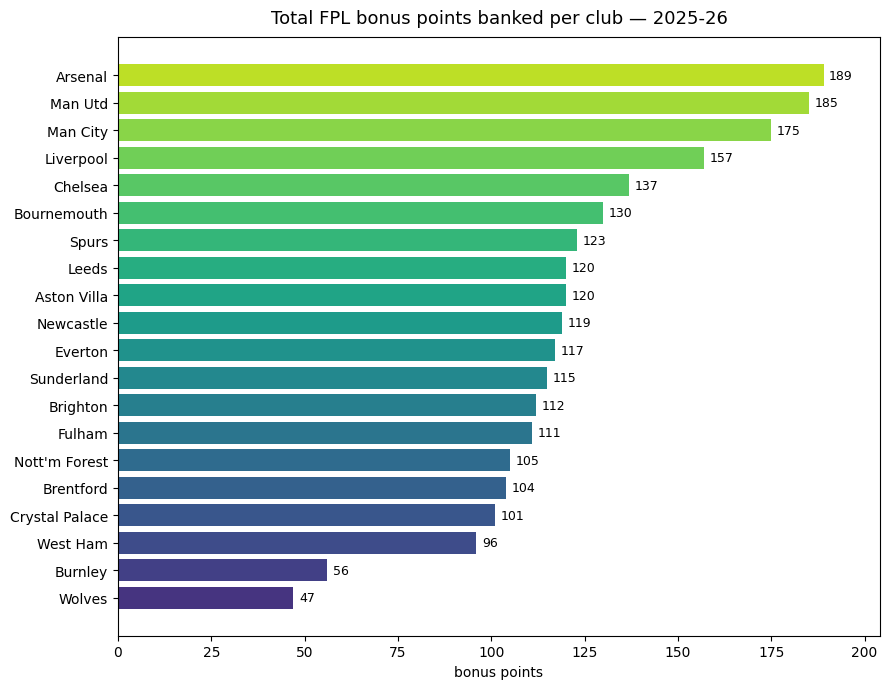

In [34]:
fig, ax = plt.subplots(figsize=(9, 7))
order = team_total.sort_values()
colors = plt.cm.viridis(np.linspace(0.15, 0.9, len(order)))
ax.barh(order.index, order.values, color=colors)
for y, v in enumerate(order.values):
    ax.text(v + 1.5, y, str(int(v)), va="center", fontsize=9)
ax.set_title(f"Total FPL bonus points banked per club — {SEASON}", fontsize=13, pad=10)
ax.set_xlabel("bonus points")
ax.margins(x=0.08)
plt.tight_layout(); plt.show()

## By position — where each club's bonus came from
Same team totals, decomposed into GK / DEF / MID / FWD. This is the "what kind of club" read:
attack-heavy bonus (Man City's FWDs, Man Utd's MIDs) vs defence-led (Crystal Palace's DEFs).

In [35]:
team_pos = (gw.pivot_table(index="team", columns="position", values="bonus",
                           aggfunc="sum", fill_value=0)
              .reindex(columns=POS_ORDER, fill_value=0).astype(int))
team_pos["TOTAL"] = team_pos.sum(axis=1)
team_pos = team_pos.sort_values("TOTAL", ascending=False)
team_pos

position,GK,DEF,MID,FWD,TOTAL
team,,,,,
Arsenal,11,68,91,19,189
Man Utd,11,46,103,25,185
Man City,5,56,71,43,175
Liverpool,10,31,90,26,157
Chelsea,7,40,59,31,137
Bournemouth,5,45,56,24,130
Spurs,6,34,61,22,123
Aston Villa,11,26,55,28,120
Leeds,6,33,53,28,120


In [36]:
# 100% within-team share — what fraction of each club's bonus each line earned
share = team_pos[POS_ORDER].div(team_pos["TOTAL"], axis=0) * 100
share.round(1)

position,GK,DEF,MID,FWD
team,,,,
Arsenal,5.8,36.0,48.1,10.1
Man Utd,5.9,24.9,55.7,13.5
Man City,2.9,32.0,40.6,24.6
Liverpool,6.4,19.7,57.3,16.6
Chelsea,5.1,29.2,43.1,22.6
Bournemouth,3.8,34.6,43.1,18.5
Spurs,4.9,27.6,49.6,17.9
Aston Villa,9.2,21.7,45.8,23.3
Leeds,5.0,27.5,44.2,23.3


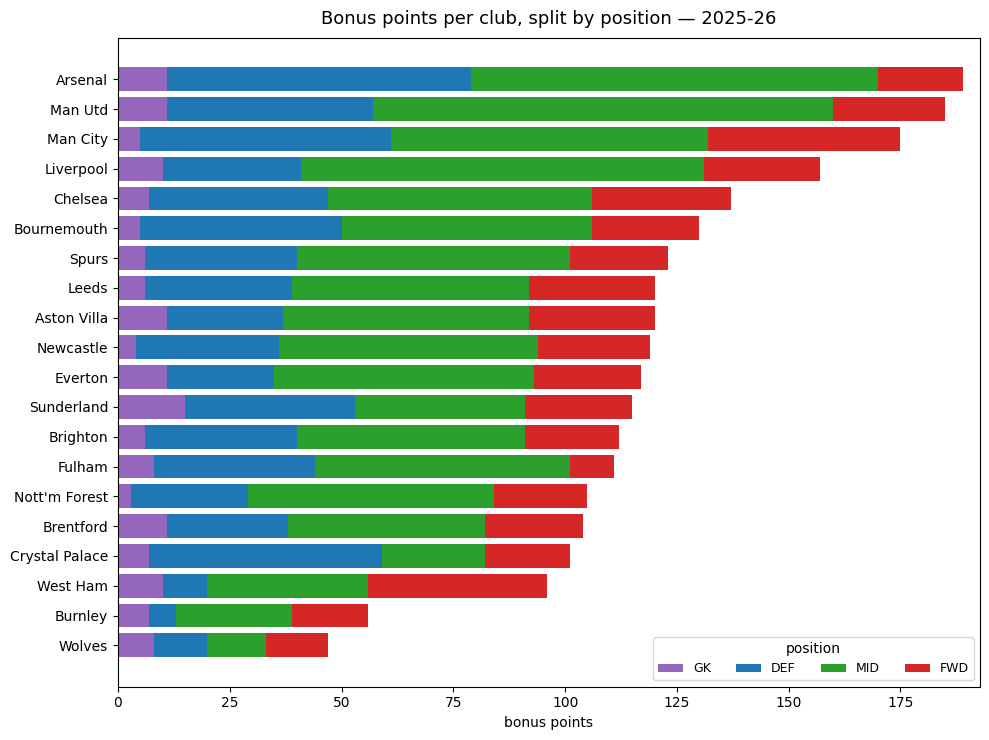

In [37]:
fig, ax = plt.subplots(figsize=(10, 7.5))
order = team_pos.sort_values("TOTAL")           # smallest at bottom
pos_colors = {"GK": "#9467bd", "DEF": "#1f77b4", "MID": "#2ca02c", "FWD": "#d62728"}
left = np.zeros(len(order))
for pos in POS_ORDER:
    vals = order[pos].values
    ax.barh(order.index, vals, left=left, color=pos_colors[pos], label=pos)
    left += vals
ax.set_title(f"Bonus points per club, split by position — {SEASON}", fontsize=13, pad=10)
ax.set_xlabel("bonus points")
ax.legend(title="position", ncol=4, loc="lower right", fontsize=9)
ax.margins(x=0.02)
plt.tight_layout(); plt.show()

In [38]:
# League-wide: which position earns bonus at all?
league_pos = gw.groupby("position")["bonus"].sum().reindex(POS_ORDER).astype(int)
league_pos_pct = (league_pos / league * 100).round(1)
pd.DataFrame({"bonus": league_pos, "%league": league_pos_pct})

,bonus,%league
position,,
GK,162,6.7
DEF,676,27.9
MID,1098,45.4
FWD,483,20.0


## By player — the individual bonus magnets
Who personally banked the bonus. Leaderboard of the top earners, coloured by position, with
their club labelled — the granular layer under the team totals above.

In [39]:
player = (gw.groupby(["name", "team", "position"])["bonus"].sum()
            .reset_index().sort_values("bonus", ascending=False).reset_index(drop=True))
player.head(TOP_PLAYERS)

,name,team,position,bonus
0,Erling Haaland,Man City,FWD,43
1,Bruno Borges Fernandes,Man Utd,MID,41
2,Gabriel dos Santos Magalhães,Arsenal,DEF,30
3,João Pedro Junqueira de Jesus,Chelsea,FWD,30
4,Jarrod Bowen,West Ham,FWD,28
5,Ollie Watkins,Aston Villa,FWD,26
6,Declan Rice,Arsenal,MID,23
7,Igor Thiago Nascimento Rodrigues,Brentford,FWD,22
8,Hugo Ekitiké,Liverpool,FWD,22
9,Bruno Guimarães Rodriguez Moura,Newcastle,MID,22


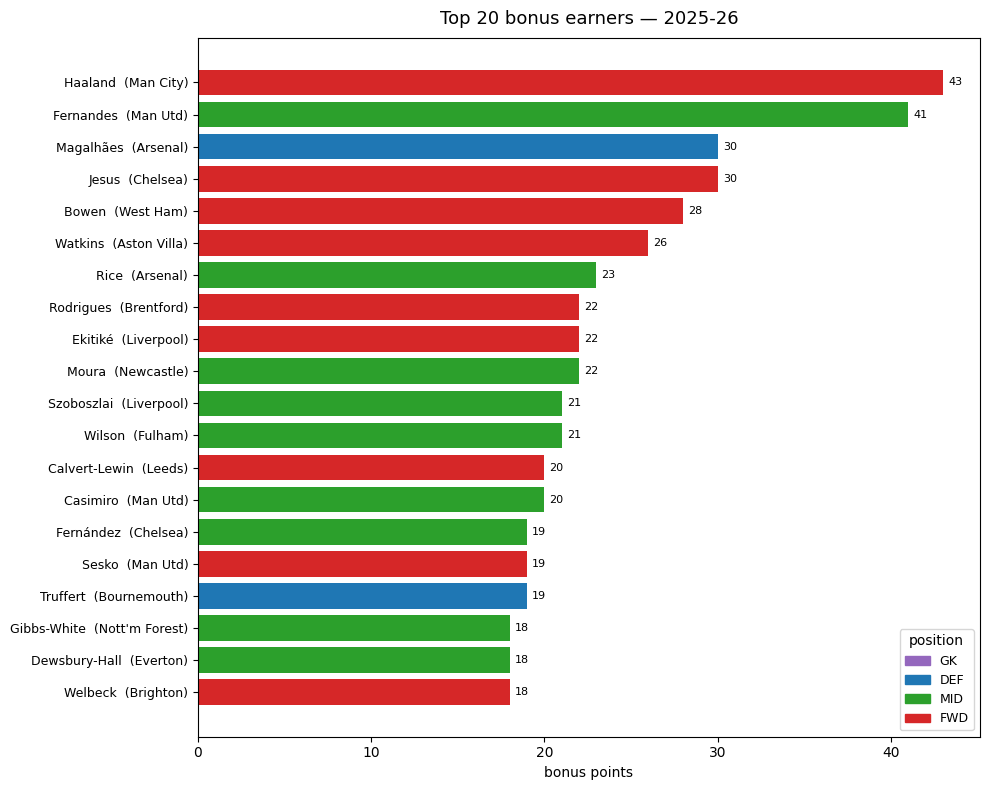

In [40]:
top = player.head(TOP_PLAYERS).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 8))
bar_colors = [pos_colors[p] for p in top["position"]]
labels = [f"{n.split()[-1] if len(n.split())>1 else n}  ({t})"
          for n, t in zip(top["name"], top["team"])]
ax.barh(range(len(top)), top["bonus"], color=bar_colors)
ax.set_yticks(range(len(top)))
ax.set_yticklabels(labels, fontsize=9)
for y, v in enumerate(top["bonus"].values):
    ax.text(v + 0.3, y, str(int(v)), va="center", fontsize=8)
handles = [plt.Rectangle((0,0),1,1,color=pos_colors[p]) for p in POS_ORDER]
ax.legend(handles, POS_ORDER, title="position", loc="lower right", fontsize=9)
ax.set_title(f"Top {TOP_PLAYERS} bonus earners — {SEASON}", fontsize=13, pad=10)
ax.set_xlabel("bonus points")
ax.margins(x=0.05)
plt.tight_layout(); plt.show()

In [41]:
# Each club's single biggest bonus contributor, and how concentrated the haul is
top_per_team = (player.sort_values("bonus", ascending=False)
                      .groupby("team").head(2)
                      .set_index("team")[["name", "position", "bonus"]])
top_per_team = top_per_team.join(team_total.rename("team_total"))
top_per_team["%of_team"] = (top_per_team["bonus"] / top_per_team["team_total"] * 100).round(1)
top_per_team.sort_values("%of_team", ascending=False)

,name,position,bonus,team_total,%of_team
team,,,,,
West Ham,Jarrod Bowen,FWD,28,96,29.2
Man City,Erling Haaland,FWD,43,175,24.6
Man Utd,Bruno Borges Fernandes,MID,41,185,22.2
Chelsea,João Pedro Junqueira de Jesus,FWD,30,137,21.9
Aston Villa,Ollie Watkins,FWD,26,120,21.7
Brentford,Igor Thiago Nascimento Rodrigues,FWD,22,104,21.2
Burnley,Zian Flemming,FWD,11,56,19.6
Wolves,Mateus Mané,FWD,9,47,19.1
Fulham,Harry Wilson,MID,21,111,18.9


## By concentration — top-3 players vs the rest
Every club's bonus split into its **three biggest earners** and **everyone else**. This is the
"how reliant is the club on a few names" read: a tall top-3 slice means the haul rests on a
handful of assets, a fat "rest" slice means bonus is spread across the squad.

In [42]:
# Split each club's bonus into its top-3 earners vs the rest
ranked = player.sort_values(["team", "bonus"], ascending=[True, False])
ranked["rank_in_team"] = ranked.groupby("team").cumcount() + 1
ranked["bucket"] = np.where(ranked["rank_in_team"] <= 3, "top3", "rest")

conc = (ranked.groupby(["team", "bucket"])["bonus"].sum()
              .unstack(fill_value=0).reindex(columns=["top3", "rest"], fill_value=0)
              .astype(int))
conc["TOTAL"] = conc.sum(axis=1)
conc["top3_%"] = (conc["top3"] / conc["TOTAL"] * 100).round(1)
conc = conc.sort_values("TOTAL", ascending=False)
assert conc["TOTAL"].sum() == league, "top3/rest split must be lossless"
conc

bucket,top3,rest,TOTAL,top3_%
team,,,,
Arsenal,71,118,189,37.6
Man Utd,80,105,185,43.2
Man City,75,100,175,42.9
Liverpool,60,97,157,38.2
Chelsea,60,77,137,43.8
Bournemouth,50,80,130,38.5
Spurs,44,79,123,35.8
Aston Villa,54,66,120,45.0
Leeds,45,75,120,37.5


In [43]:
# The three biggest bonus earners per club, laid out clearly (name + bonus each)
top3 = ranked[ranked["rank_in_team"] <= 3].copy()
top3["slot"] = top3["rank_in_team"].map({1: "1st", 2: "2nd", 3: "3rd"})
top3["cell"] = top3["name"] + " — " + top3["bonus"].astype(str)
top3_tbl = (top3.pivot(index="team", columns="slot", values="cell")
                .reindex(columns=["1st", "2nd", "3rd"]))
top3_tbl = top3_tbl.join(conc[["top3", "TOTAL", "top3_%"]])
top3_tbl = top3_tbl.sort_values("top3_%", ascending=False)
top3_tbl

,1st,2nd,3rd,top3,TOTAL,top3_%
team,,,,,,
West Ham,Jarrod Bowen — 28,Crysencio Summerville — 10,Tomáš Souček — 9,47,96,49.0
Wolves,Mateus Mané — 9,José Malheiro de Sá — 8,João Victor Gomes da Silva — 6,23,47,48.9
Brentford,Igor Thiago Nascimento Rodrigues — 22,Dango Ouattara — 16,Caoimhín Kelleher — 11,49,104,47.1
Nott'm Forest,Morgan Gibbs-White — 18,Elliot Anderson — 16,Neco Williams — 15,49,105,46.7
Burnley,Zian Flemming — 11,Josh Cullen — 8,Martin Dúbravka — 7,26,56,46.4
Aston Villa,Ollie Watkins — 26,Morgan Rogers — 17,Emiliano Martínez Romero — 11,54,120,45.0
Chelsea,João Pedro Junqueira de Jesus — 30,Enzo Fernández — 19,Reece James — 11,60,137,43.8
Man Utd,Bruno Borges Fernandes — 41,Carlos Henrique Casimiro — 20,Benjamin Sesko — 19,80,185,43.2
Man City,Erling Haaland — 43,Matheus Nunes — 16,Rayan Cherki — 16,75,175,42.9


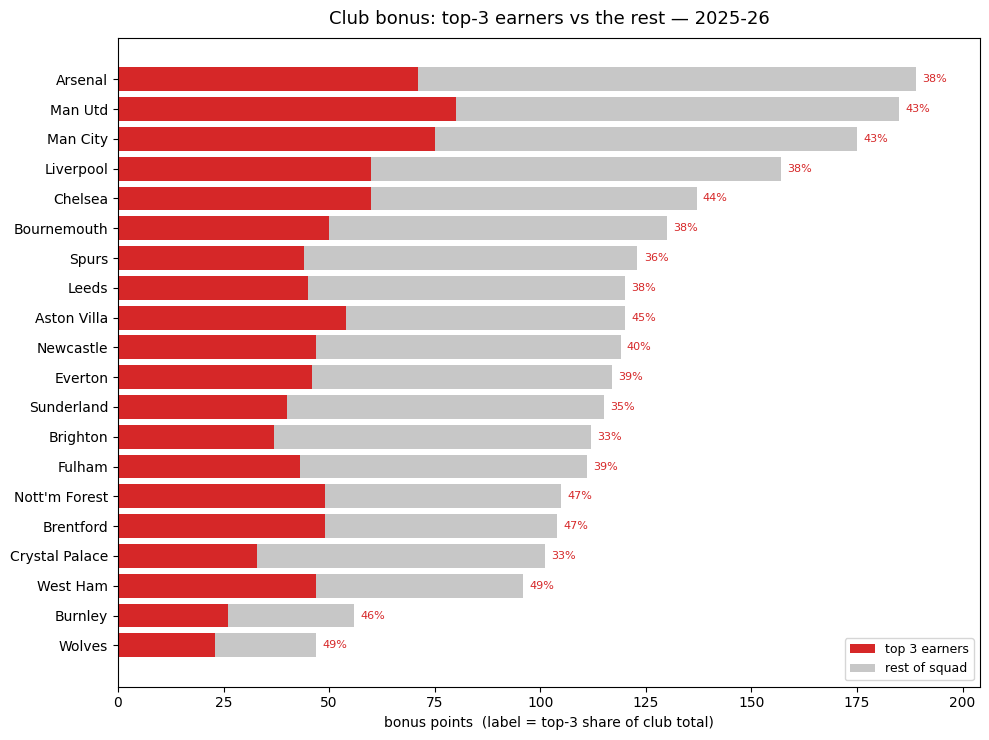

In [44]:
fig, ax = plt.subplots(figsize=(10, 7.5))
order = conc.sort_values("TOTAL")                # smallest at bottom
bucket_colors = {"top3": "#d62728", "rest": "#c7c7c7"}
left = np.zeros(len(order))
for bucket, lbl in [("top3", "top 3 earners"), ("rest", "rest of squad")]:
    vals = order[bucket].values
    ax.barh(order.index, vals, left=left, color=bucket_colors[bucket], label=lbl)
    left += vals
for y, (tot, pct) in enumerate(zip(order["TOTAL"].values, order["top3_%"].values)):
    ax.text(tot + 1.5, y, f"{pct:.0f}%", va="center", fontsize=8, color="#d62728")
ax.set_title(f"Club bonus: top-3 earners vs the rest — {SEASON}", fontsize=13, pad=10)
ax.set_xlabel("bonus points  (label = top-3 share of club total)")
ax.legend(title="", loc="lower right", fontsize=9)
ax.margins(x=0.08)
plt.tight_layout(); plt.show()

## Second-half only — top-3 vs the rest (GW 20–38)
The same top-3 / rest concentration read, but restricted to the **run-in (GW 20–38)**. Form and
minutes shift after the winter — new signings bed in, some magnets fade — so a club's second-half
top-3 names and its reliance on them can look different from the full-season picture above.

In [45]:
H2_START = 20   # second half = GW 20 onward (through GW 38)

gw_h2 = gw[gw["round"] >= H2_START]
player_h2 = (gw_h2.groupby(["name", "team", "position"])["bonus"].sum()
                  .reset_index().sort_values("bonus", ascending=False).reset_index(drop=True))

ranked_h2 = player_h2.sort_values(["team", "bonus"], ascending=[True, False])
ranked_h2["rank_in_team"] = ranked_h2.groupby("team").cumcount() + 1
ranked_h2["bucket"] = np.where(ranked_h2["rank_in_team"] <= 3, "top3", "rest")

conc_h2 = (ranked_h2.groupby(["team", "bucket"])["bonus"].sum()
                    .unstack(fill_value=0).reindex(columns=["top3", "rest"], fill_value=0)
                    .astype(int))
conc_h2["TOTAL"] = conc_h2.sum(axis=1)
conc_h2["top3_%"] = (conc_h2["top3"] / conc_h2["TOTAL"] * 100).round(1)
conc_h2 = conc_h2.sort_values("TOTAL", ascending=False)
league_h2 = int(gw_h2["bonus"].sum())
assert conc_h2["TOTAL"].sum() == league_h2, "second-half split must be lossless"
print(f"GW {H2_START}–{int(gw['round'].max())}: {league_h2:,} bonus points")
conc_h2

GW 20–38: 1,209 bonus points


bucket,top3,rest,TOTAL,top3_%
team,,,,
Man Utd,50,50,100,50.0
Arsenal,37,57,94,39.4
Man City,29,56,85,34.1
Liverpool,31,50,81,38.3
Bournemouth,29,39,68,42.6
Nott'm Forest,36,28,64,56.2
Brighton,26,38,64,40.6
Aston Villa,33,29,62,53.2
Leeds,25,35,60,41.7


In [46]:
# Second-half top-3 earners per club, name + bonus each
top3_h2 = ranked_h2[ranked_h2["rank_in_team"] <= 3].copy()
top3_h2["slot"] = top3_h2["rank_in_team"].map({1: "1st", 2: "2nd", 3: "3rd"})
top3_h2["cell"] = top3_h2["name"] + " — " + top3_h2["bonus"].astype(str)
top3_h2_tbl = (top3_h2.pivot(index="team", columns="slot", values="cell")
                      .reindex(columns=["1st", "2nd", "3rd"])
                      .join(conc_h2[["top3", "TOTAL", "top3_%"]])
                      .sort_values("top3_%", ascending=False))
top3_h2_tbl

,1st,2nd,3rd,top3,TOTAL,top3_%
team,,,,,,
Burnley,Zian Flemming — 8,Hannibal Mejbri — 4,Marcus Edwards — 2,14,18,77.8
Chelsea,João Pedro Junqueira de Jesus — 15,Enzo Fernández — 11,Cole Palmer — 10,36,53,67.9
Wolves,Mateus Mané — 9,José Malheiro de Sá — 7,João Victor Gomes da Silva — 5,21,36,58.3
Nott'm Forest,Morgan Gibbs-White — 14,Elliot Anderson — 12,Igor Jesus Maciel da Cruz — 10,36,64,56.2
Brentford,Igor Thiago Nascimento Rodrigues — 10,Dango Ouattara — 10,Caoimhín Kelleher — 9,29,53,54.7
West Ham,Jarrod Bowen — 12,Crysencio Summerville — 10,Mads Hermansen — 8,30,56,53.6
Everton,Norberto Bercique Gomes Betuncal — 14,Thierno Barry — 9,Kiernan Dewsbury-Hall — 8,31,58,53.4
Aston Villa,Ollie Watkins — 18,Emiliano Martínez Romero — 8,Morgan Rogers — 7,33,62,53.2
Newcastle,William Osula — 13,Malick Thiaw — 8,Bruno Guimarães Rodriguez Moura — 7,28,55,50.9


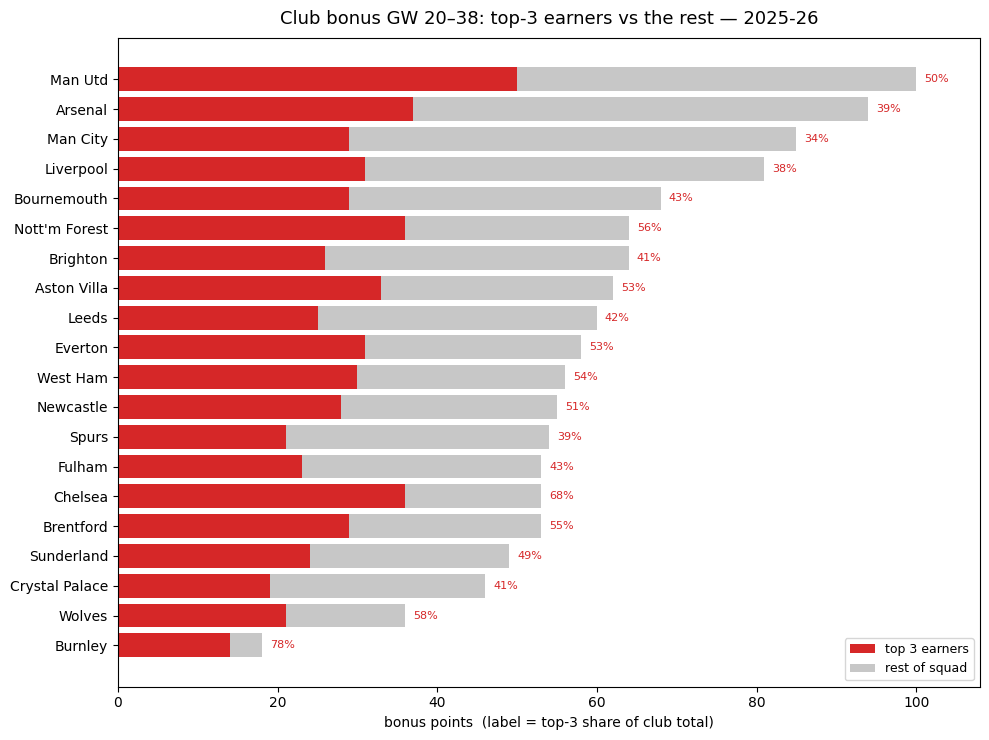

In [47]:
fig, ax = plt.subplots(figsize=(10, 7.5))
order = conc_h2.sort_values("TOTAL")
left = np.zeros(len(order))
for bucket, lbl in [("top3", "top 3 earners"), ("rest", "rest of squad")]:
    vals = order[bucket].values
    ax.barh(order.index, vals, left=left, color=bucket_colors[bucket], label=lbl)
    left += vals
for y, (tot, pct) in enumerate(zip(order["TOTAL"].values, order["top3_%"].values)):
    ax.text(tot + 1.0, y, f"{pct:.0f}%", va="center", fontsize=8, color="#d62728")
ax.set_title(f"Club bonus GW {H2_START}–38: top-3 earners vs the rest — {SEASON}",
             fontsize=13, pad=10)
ax.set_xlabel("bonus points  (label = top-3 share of club total)")
ax.legend(title="", loc="lower right", fontsize=9)
ax.margins(x=0.08)
plt.tight_layout(); plt.show()

## Headline reads
- **Arsenal (189)** lead the league for bonus banked, with **Man Utd (185)** and **Man City
  (175)** close behind; **Wolves (47)** and **Burnley (56)** trail badly — bottom-table
  attacking output shows up directly in bonus.
- **Midfield is the bonus engine** league-wide (~45% of all bonus), then DEF (~28%), FWD
  (~20%), GK just ~7% — BPS rewards the on-ball, defensive-action-heavy midfield role.
- **Position mix is a fingerprint:** Man Utd's bonus is MID-led (103 of 185), Man City's tilts
  to FWD (Haaland), while **Crystal Palace** is the outlier — DEF (52) outscores MID (23).
- **Individual magnets:** Haaland (43) and Bruno Fernandes (41) tower over the field; the
  `top-per-team` table shows how much each club leans on one player for its bonus.

## Caveats
- Team label is the player's per-GW `team`; mid-season transfers split a player's bonus across
  both clubs (correct for *club* attribution, but a moved player appears twice by name).
- Bonus is taken as the raw awarded value — this is a retrospective of *what happened*, not a
  BPS-model prediction of what a club "should" earn.
- Single completed season (2025/26); no fixture or repeatability read here.